<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Ejercicios/Soluciones/01_Taller_Sentimiento_RL_NB_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Taller práctico: análisis de sentimiento con regresión logística y Naive Bayes (solución)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Solución de referencia del taller [`01_Taller_Sentimiento_RL_NB.ipynb`](../01_Taller_Sentimiento_RL_NB.ipynb).

Hay muchas soluciones válidas: esta es una de ellas. Compara tus resultados y, sobre todo, tus conclusiones.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Ejercicio 1. Exploración y división de los datos</span>](#ejercicio-1)
- [<span style="color: #005C99;">Ejercicio 2. Preprocesamiento con manejo de negaciones</span>](#ejercicio-2)
- [<span style="color: #005C99;">Ejercicio 3. Regresión logística regularizada desde cero</span>](#ejercicio-3)
- [<span style="color: #005C99;">Ejercicio 4. Naive Bayes y la selección del suavizado</span>](#ejercicio-4)
- [<span style="color: #005C99;">Ejercicio 5. Comparación de modelos y análisis de errores</span>](#ejercicio-5)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn scipy nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import string
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

import nltk
from nltk.corpus import movie_reviews

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

SEED = 42
np.random.seed(SEED)

for recurso in ["movie_reviews", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Exploración y división de los datos</h2>

**Objetivo:** cargar el corpus, entender su estructura y crear una división entrenamiento/prueba sin fugas de información.

`movie_reviews` contiene 2 000 reseñas de películas en inglés, 1 000 positivas (`pos`) y 1 000 negativas (`neg`). Cada reseña es un archivo; se accede con `movie_reviews.fileids(categoria)` y `movie_reviews.raw(fileid)`.

1. Construye un `DataFrame` llamado `df` con las columnas `texto` y `etiqueta` (1 = positiva, 0 = negativa).
2. Agrega una columna `n_palabras` y reporta la media, la mediana y el máximo de palabras por reseña, por clase. ¿Hay diferencia de longitud entre clases?
3. Divide en entrenamiento (80 %) y prueba (20 %) de forma **estratificada** con `random_state=SEED`. Llama a los resultados `X_train_txt`, `X_test_txt`, `y_train`, `y_test` (las etiquetas como arreglos de NumPy).
4. Compara la longitud típica de estas reseñas con la de los tweets del cuaderno 03 (≈ 10–20 palabras). ¿Qué implicaciones crees que tiene para la representación?

In [3]:
filas = [(movie_reviews.raw(fid), 1 if cat == "pos" else 0)
         for cat in ["pos", "neg"] for fid in movie_reviews.fileids(cat)]
df = pd.DataFrame(filas, columns=["texto", "etiqueta"])
df["n_palabras"] = df.texto.str.split().str.len()

print(df.etiqueta.value_counts())
df.groupby("etiqueta").n_palabras.agg(["mean", "median", "max"]).round(1)

etiqueta
1    1000
0    1000
Name: count, dtype: int64


,mean,median,max
etiqueta,,,
0,705.6,668.5,2181
1,787.1,731.5,2678


In [4]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df.texto.tolist(), df.etiqueta.values, test_size=0.2, stratify=df.etiqueta, random_state=SEED
)
print(f"Entrenamiento: {len(X_train_txt)} | Prueba: {len(X_test_txt)} | Positivos en train: {y_train.mean():.2f}")

Entrenamiento: 1600 | Prueba: 400 | Positivos en train: 0.50


**Respuestas:**

- El corpus está perfectamente balanceado. Las reseñas positivas son, en promedio, un poco más largas que las negativas, pero la diferencia es pequeña frente a la variación dentro de cada clase, así que la longitud por sí sola no es una buena característica.
- Las reseñas tienen del orden de **700 palabras**, unas 40 veces más que un tweet. Cada documento activa muchas más dimensiones del vocabulario y las sumas de frecuencias crecen con la longitud, así que hay que **normalizar** (TF-IDF con norma L2 lo hace). Además, una reseña larga suele mezclar aspectos positivos y negativos (*"la actuación es buena, pero el guion es terrible"*), lo que hace la tarea más difícil que con tweets cortos.

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. Preprocesamiento con manejo de negaciones</h2>

**Objetivo:** implementar el marcado de negaciones, una técnica clásica para que los modelos de bolsa de palabras capten frases como *not good*.

Vimos que los modelos de bolsa de palabras no entienden *"not good"*. Una solución simple (Das & Chen, 2001; Pang et al., 2002) es **añadir el prefijo `NOT_` a cada palabra que sigue a una negación, hasta el siguiente signo de puntuación**:

```text
"i did n't like this movie , but the actors were great"
 -> ['i', 'did', "n't", 'NOT_like', 'NOT_this', 'NOT_movie', ',', 'but', 'the', 'actors', 'were', 'great']
```

1. Implementa `tokenizar(texto)` que pase a minúsculas y tokenice con `nltk.word_tokenize`.
2. Implementa `marcar_negaciones(tokens)` usando el conjunto `NEGACIONES` y la puntuación `PUNTUACION` dados.
3. Implementa `preprocesar(texto, negaciones=True)` que tokenice, aplique (opcionalmente) el marcado y **elimine** los signos de puntuación.
4. Pruébala con las frases de ejemplo.

In [5]:
NEGACIONES = {"not", "no", "never", "n't", "nothing", "nobody", "nor", "neither", "without", "cannot"}
PUNTUACION = set(string.punctuation)


def tokenizar(texto):
    return nltk.word_tokenize(texto.lower())


def marcar_negaciones(tokens):
    resultado, negando = [], False
    for t in tokens:
        if t in PUNTUACION:
            negando = False
            resultado.append(t)
        elif t in NEGACIONES:
            negando = True
            resultado.append(t)
        else:
            resultado.append("NOT_" + t if negando else t)
    return resultado


def preprocesar(texto, negaciones=True):
    tokens = tokenizar(texto)
    if negaciones:
        tokens = marcar_negaciones(tokens)
    return [t for t in tokens if t not in PUNTUACION]


for frase in ["I didn't like this movie, but the actors were great.",
              "Not a bad film at all. Never boring!"]:
    print(preprocesar(frase))

['i', 'did', "n't", 'NOT_like', 'NOT_this', 'NOT_movie', 'but', 'the', 'actors', 'were', 'great']
['not', 'NOT_a', 'NOT_bad', 'NOT_film', 'NOT_at', 'NOT_all', 'never', 'NOT_boring']


Observa que `word_tokenize` separa *didn't* en `did` + `n't`, por eso incluimos `n't` en las negaciones. En *"Not a bad film"* el marcado produce `NOT_bad`, una característica distinta de `bad`, que el modelo puede aprender como positiva.

In [6]:
# Tokenizamos una sola vez: lo reutilizaremos en los siguientes ejercicios
tok_train = [preprocesar(t) for t in X_train_txt]
tok_test = [preprocesar(t) for t in X_test_txt]
tok_train_sin = [preprocesar(t, negaciones=False) for t in X_train_txt]
tok_test_sin = [preprocesar(t, negaciones=False) for t in X_test_txt]

n_marcados = sum(t.startswith("NOT_") for doc in tok_train for t in doc)
print(f"Tokens marcados con NOT_ en entrenamiento: {n_marcados:,}")

Tokens marcados con NOT_ en entrenamiento: 84,436


---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Regresión logística regularizada desde cero</h2>

**Objetivo:** implementar la regresión logística con regularización L2 sobre una matriz TF-IDF dispersa y verificarla contra scikit-learn.

En el cuaderno 03 implementamos la regresión logística con 3 características. Ahora tendremos **decenas de miles** (una por palabra), así que hay riesgo de sobreajuste y necesitamos **regularización L2**:

$$J(\boldsymbol\theta) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log h^{(i)} + (1 - y^{(i)}) \log (1 - h^{(i)}) \right] + \frac{\lambda}{2m} \sum_{j=1}^{n} \theta_j^2$$

$$\nabla_{\boldsymbol\theta} J = \frac{1}{m} \mathbf{X}^\top (\mathbf{h} - \mathbf{y}) + \frac{\lambda}{m} \boldsymbol\theta, \qquad \nabla_{b} J = \frac{1}{m} \sum_i (h^{(i)} - y^{(i)})$$

(el sesgo $b$ no se regulariza).

1. Vectoriza con `TfidfVectorizer(tokenizer=lambda x: x, preprocessor=lambda x: x, token_pattern=None, min_df=2)` sobre `tok_train` y transforma `tok_test`. Llama a las matrices `Xtr` y `Xte`.
2. Implementa `entrenar_logistica(X, y, lam, alpha, n_iter)` con descenso del gradiente. Debe funcionar con matrices dispersas: usa `X @ theta` y `X.T @ v`, nunca `X.toarray()`. Devuelve `theta`, `b` y el historial del costo.
3. Entrena con `lam=1.0`, `alpha=5.0` y `n_iter=1000`, y grafica el costo.
4. Reporta la exactitud en prueba.
5. Compara con `LogisticRegression(C=...)` de scikit-learn. Ten en cuenta que scikit-learn minimiza $C \sum_i \text{logloss}_i + \frac{1}{2}\|\boldsymbol\theta\|^2$, así que la equivalencia es $C = 1/\lambda$. ¿Qué tan parecidas son las predicciones?

In [7]:
identidad = lambda x: x
vec = TfidfVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None, min_df=2)
Xtr = vec.fit_transform(tok_train)
Xte = vec.transform(tok_test)
print("Xtr:", Xtr.shape, "| tipo:", type(Xtr).__name__)

Xtr: (1600, 26313) | tipo: csr_matrix


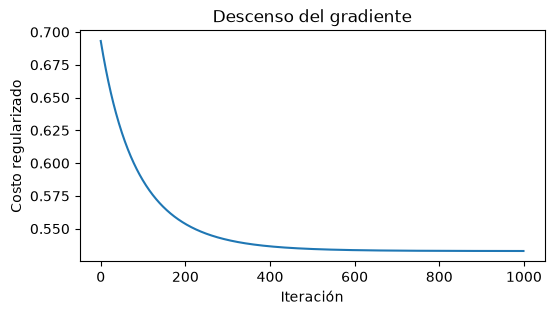

Exactitud (implementación propia): 0.8250


In [8]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def entrenar_logistica(X, y, lam=1.0, alpha=1.0, n_iter=1000, eps=1e-12):
    m, n = X.shape
    theta, b = np.zeros(n), 0.0
    historial = []
    for _ in range(n_iter):
        h = sigmoide(X @ theta + b)
        error = h - y
        theta -= alpha * (X.T @ error / m + lam / m * theta)
        b -= alpha * error.mean()
        costo = -np.mean(y * np.log(h + eps) + (1 - y) * np.log(1 - h + eps)) + lam / (2 * m) * theta @ theta
        historial.append(costo)
    return theta, b, historial


theta, b, historial = entrenar_logistica(Xtr, y_train, lam=1.0, alpha=5.0, n_iter=1000)

plt.figure(figsize=(6, 3))
plt.plot(historial)
plt.xlabel("Iteración")
plt.ylabel("Costo regularizado")
plt.title("Descenso del gradiente")
plt.show()

pred_propia = (sigmoide(Xte @ theta + b) >= 0.5).astype(int)
print(f"Exactitud (implementación propia): {accuracy_score(y_test, pred_propia):.4f}")

In [9]:
sk = LogisticRegression(C=1 / 1.0, max_iter=5000).fit(Xtr, y_train)
pred_sk = sk.predict(Xte)
print(f"Exactitud scikit-learn:  {accuracy_score(y_test, pred_sk):.4f}")
print(f"Predicciones idénticas: {np.mean(pred_sk == pred_propia):.2%}")
print(f"Correlación de los pesos: {np.corrcoef(theta, sk.coef_[0])[0, 1]:.3f}")

Exactitud scikit-learn:  0.8200
Predicciones idénticas: 99.50%
Correlación de los pesos: 1.000


**Interpretación:** las dos implementaciones minimizan la misma función, así que los pesos están muy correlacionados y casi todas las predicciones coinciden. Las pequeñas diferencias se deben a que el descenso del gradiente con 1 000 iteraciones aún no ha convergido del todo, mientras que scikit-learn usa un optimizador de segundo orden (L-BFGS) que llega al mínimo exacto. Con más iteraciones las dos soluciones se acercarían todavía más.

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. Naive Bayes y la selección del suavizado</h2>

**Objetivo:** implementar Naive Bayes multinomial con suavizado aditivo y elegir $\alpha$ con validación cruzada, sin tocar el conjunto de prueba.

1. Implementa `entrenar_nb(tokens_por_doc, y, alpha)` y `predecir_nb(modelo, tokens_por_doc)` (puedes reutilizar la lógica del cuaderno 04, pero esta vez $\alpha$ es un parámetro).
2. Verifica tu implementación: con `alpha=1` debe dar las mismas predicciones que `make_pipeline(CountVectorizer(...), MultinomialNB(alpha=1))` usando el mismo tokenizado.
3. Usa **validación cruzada estratificada de 5 particiones** (sobre el conjunto de entrenamiento) para evaluar $\alpha \in \{0.01, 0.05, 0.1, 0.5, 1, 2, 5\}$. Puedes usar `cross_val_score` con el pipeline de scikit-learn.
4. Grafica la exactitud media (con su desviación estándar) contra $\alpha$ en escala logarítmica.
5. Elige el mejor $\alpha$, reentrena con todo el conjunto de entrenamiento y evalúa **una sola vez** en prueba.
6. ¿Qué ocurre con valores de $\alpha$ muy pequeños y muy grandes? Explica por qué.

In [10]:
def entrenar_nb(tokens_por_doc, y, alpha=1.0):
    conteos = {0: Counter(), 1: Counter()}
    for tokens, etiqueta in zip(tokens_por_doc, y):
        conteos[int(etiqueta)].update(tokens)
    vocab = set(conteos[0]) | set(conteos[1])
    n = {c: sum(conteos[c].values()) for c in (0, 1)}
    V = len(vocab)
    loglik = {w: np.log((conteos[1][w] + alpha) / (n[1] + alpha * V))
                 - np.log((conteos[0][w] + alpha) / (n[0] + alpha * V)) for w in vocab}
    logprior = np.log(np.mean(y)) - np.log(1 - np.mean(y))
    return logprior, loglik


def predecir_nb(modelo, tokens_por_doc):
    logprior, loglik = modelo
    return np.array([int(logprior + sum(loglik.get(w, 0.0) for w in doc) > 0) for doc in tokens_por_doc])


pred_propia = predecir_nb(entrenar_nb(tok_train, y_train, alpha=1.0), tok_test)

identidad = lambda x: x
nb_sk = make_pipeline(CountVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None),
                      MultinomialNB(alpha=1.0)).fit(tok_train, y_train)
print(f"Exactitud propia: {accuracy_score(y_test, pred_propia):.4f}")
print(f"Coincidencia con MultinomialNB: {np.mean(nb_sk.predict(tok_test) == pred_propia):.2%}")

Exactitud propia: 0.8175
Coincidencia con MultinomialNB: 100.00%


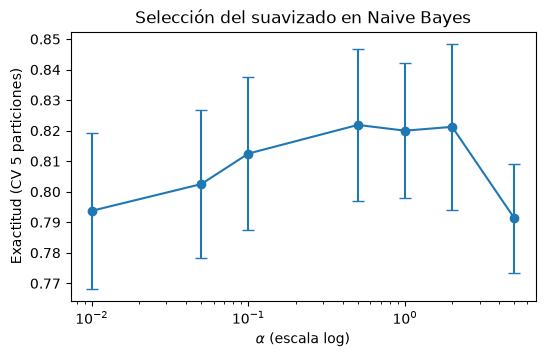

Mejor alpha según validación cruzada: 0.5


In [11]:
alphas = [0.01, 0.05, 0.1, 0.5, 1, 2, 5]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
medias, desvs = [], []
for a in alphas:
    pipe = make_pipeline(CountVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None),
                         MultinomialNB(alpha=a))
    scores = cross_val_score(pipe, tok_train, y_train, cv=cv, scoring="accuracy")
    medias.append(scores.mean())
    desvs.append(scores.std())

plt.figure(figsize=(6, 3.5))
plt.errorbar(alphas, medias, yerr=desvs, marker="o", capsize=4)
plt.xscale("log")
plt.xlabel(r"$\alpha$ (escala log)")
plt.ylabel("Exactitud (CV 5 particiones)")
plt.title("Selección del suavizado en Naive Bayes")
plt.show()

mejor_alpha = alphas[int(np.argmax(medias))]
print(f"Mejor alpha según validación cruzada: {mejor_alpha}")

In [12]:
pred_final = predecir_nb(entrenar_nb(tok_train, y_train, alpha=mejor_alpha), tok_test)
print(f"Exactitud en prueba con alpha={mejor_alpha}: {accuracy_score(y_test, pred_final):.4f}")

Exactitud en prueba con alpha=0.5: 0.8125


**Interpretación:**

- Con $\alpha$ **muy pequeño**, una palabra vista solo en una clase recibe una razón de verosimilitud enorme: el modelo confía demasiado en palabras raras (que pueden ser nombres de actores o películas) y **sobreajusta**.
- Con $\alpha$ **muy grande**, todas las probabilidades se acercan a la distribución uniforme $1/|V|$, las razones $\lambda(w)$ se aplastan hacia cero y el modelo pierde información: **subajusta**.
- El valor óptimo equilibra ambos efectos. Lo elegimos con validación cruzada **solo sobre entrenamiento**; el conjunto de prueba se usa una única vez al final para no sesgar la estimación del desempeño.

---

<a id="ejercicio-5"></a>
<h2 style="color: #007ACC;">Ejercicio 5. Comparación de modelos y análisis de errores</h2>

**Objetivo:** comparar de forma justa los modelos y variantes de preprocesamiento, e interpretar qué aprendieron y en qué se equivocan.

1. Evalúa en prueba (F1) las cuatro combinaciones: {Naive Bayes, Regresión logística} × {con marcado de negaciones, sin marcado}. Para la regresión logística usa `TfidfVectorizer` y elige `C` con `GridSearchCV` (5 particiones) entre `[0.1, 1, 10, 100]`; para Naive Bayes usa el `mejor_alpha` del ejercicio 4. Presenta los resultados en una tabla.
2. Con el mejor modelo de regresión logística, muestra las 15 características con peso más positivo y las 15 con peso más negativo. ¿Aparecen características `NOT_`? ¿Tienen sentido?
3. Muestra los 3 errores en los que el modelo estaba más seguro (probabilidad más lejana a 0.5) con un fragmento del texto. Lee al menos uno y explica por qué crees que falló.
4. Conclusión: ¿qué modelo recomendarías y por qué? ¿Qué limitaciones comparten?

In [13]:
identidad = lambda x: x
resultados = []
mejores_lr = {}
for nombre_prep, (tr, te) in {"con negaciones": (tok_train, tok_test),
                              "sin negaciones": (tok_train_sin, tok_test_sin)}.items():
    nb = make_pipeline(CountVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None),
                       MultinomialNB(alpha=mejor_alpha)).fit(tr, y_train)
    resultados.append(("Naive Bayes", nombre_prep, f1_score(y_test, nb.predict(te)), f"alpha={mejor_alpha}"))

    lr = GridSearchCV(
        make_pipeline(TfidfVectorizer(tokenizer=identidad, preprocessor=identidad, token_pattern=None, min_df=2),
                      LogisticRegression(max_iter=5000)),
        param_grid={"logisticregression__C": [0.1, 1, 10, 100]}, cv=5, scoring="f1",
    ).fit(tr, y_train)
    mejores_lr[nombre_prep] = lr.best_estimator_
    resultados.append(("Regresión logística", nombre_prep, f1_score(y_test, lr.predict(te)),
                       f"C={lr.best_params_['logisticregression__C']}"))

pd.DataFrame(resultados, columns=["modelo", "preprocesamiento", "F1 prueba", "hiperparámetro"]).round(4)

,modelo,preprocesamiento,F1 prueba,hiperparámetro
0,Naive Bayes,con negaciones,0.8139,alpha=0.5
1,Regresión logística,con negaciones,0.8723,C=100
2,Naive Bayes,sin negaciones,0.8060,alpha=0.5
3,Regresión logística,sin negaciones,0.8599,C=100


In [14]:
modelo = mejores_lr["con negaciones"]
vocab = modelo[0].get_feature_names_out()
pesos = modelo[1].coef_[0]
orden = np.argsort(pesos)
pd.DataFrame({
    "más negativas": vocab[orden[:15]],
    "peso (-)": pesos[orden[:15]].round(2),
    "más positivas": vocab[orden[::-1][:15]],
    "peso (+)": pesos[orden[::-1][:15]].round(2),
})

,más negativas,peso (-),más positivas,peso (+)
0,bad,-15.03,and,9.16
1,only,-9.14,great,7.52
2,NOT_to,-8.49,very,7.14
3,worst,-8.38,fun,6.53
4,plot,-7.23,job,5.74
5,nothing,-7.22,truman,5.68
6,boring,-7.00,excellent,5.39
7,unfortunately,-7.00,overall,5.32
8,NOT_enough,-6.61,also,5.04
9,supposed,-6.21,mulan,5.01


In [15]:
no_feats = [(w, p) for w, p in zip(vocab, pesos) if w.startswith("NOT_")]
no_feats.sort(key=lambda x: x[1])
print("Características NOT_ más negativas:", [w for w, _ in no_feats[:8]])
print("Características NOT_ más positivas:", [w for w, _ in no_feats[-8:]])

Características NOT_ más negativas: ['NOT_to', 'NOT_enough', 'NOT_even', 'NOT_a', 'NOT_funny', 'NOT_his', 'NOT_characters', 'NOT_reason']
Características NOT_ más positivas: ['NOT_i', 'NOT_over', 'NOT_other', 'NOT_seen', 'NOT_``', 'NOT_quite', 'NOT_you', 'NOT_as']


In [16]:
probs = modelo.predict_proba(tok_test)[:, 1]
errores = np.where((probs >= 0.5) != y_test)[0]
peores = errores[np.argsort(-np.abs(probs[errores] - 0.5))][:3]
for i in peores:
    real = "positiva" if y_test[i] else "negativa"
    print(f"Real: {real} | P(positiva) = {probs[i]:.3f}")
    print(" ".join(X_test_txt[i].split())[:600], "...\n")

Real: negativa | P(positiva) = 0.985
miramax " disinvited " on-line media from press screenings of scream 3 . they ostensibly feared that folks like me would write spoiler-filled reviews and post them prior to the film's february 4th release date-unsound reasoning . you see , 'net critics established enough to be on any sort of vip list are professionals-miramax surely knows the difference between a member of the on-line film critics society ( ofcs ) and the type of fanboy who posts spy reports at ain't it cool news . no , the ? mini major' was afraid we'd let a bigger cat out of the bag than whodunit , that scream 3 is a dismal  ...

Real: positiva | P(positiva) = 0.072
for a movie about disco-era excess , " 54 " comes up surprisingly short on the sleazy happenings at the titular late 1970s and early 1980s manhattan dance club . think of it as a sort of " boogie nights " -lite - where that similarly-structured and -set portrayal of the porn industry was loaded with salacious goings-on

**Interpretación y conclusiones:**

- La regresión logística supera a Naive Bayes por unos 5–6 puntos de F1, una diferencia clara. El marcado de negaciones mejora ambos modelos en alrededor de un punto. Con un conjunto de prueba de 400 reseñas, esa última mejora está dentro del ruido estadístico: para afirmarla habría que usar validación cruzada repetida o un test estadístico.
- Los pesos de la regresión logística son muy interpretables: *bad*, *worst*, *boring*, *ridiculous* o *unfortunately* empujan hacia negativo; *great*, *fun*, *excellent* o *terrific* hacia positivo. También aparecen títulos de películas concretas (*truman*, *mulan*, *matrix*): el modelo memoriza películas que en este corpus recibieron buenas críticas, una forma de sobreajuste que no generalizaría a reseñas de otras películas. El valor `C=100` (regularización débil) favorece este efecto.
- Algunas características `NOT_` tienen sentido (*NOT_funny* y *NOT_enough* son negativas), pero muchas son ruido (*NOT_to*, *NOT_a*): el alcance de la negación hasta el siguiente signo de puntuación es una aproximación burda que marca demasiadas palabras.
- Los errores más seguros suelen ser reseñas que **resumen la trama** con mucho vocabulario de un tono (violencia, tristeza) mientras la opinión real está en pocas frases, o reseñas con **contraste** (*"I expected to hate it, but..."*) e ironía. Un modelo de bolsa de palabras no puede distinguir qué partes del texto expresan la opinión del autor.
- **Recomendación:** para este volumen de datos ambos modelos son buenas líneas base. Naive Bayes es más rápido y casi no tiene hiperparámetros; la regresión logística permite ajustar mejor la regularización y da probabilidades mejor calibradas. Ambos comparten las limitaciones de la bolsa de palabras: ignoran el orden, el alcance de las negaciones solo se aproxima y no generalizan entre sinónimos.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Vajjala, S., Majumder, B., Gupta, A. & Surana, H. (2020). *Practical Natural Language Processing*. O'Reilly Media.
- Documentación de scikit-learn: *Working With Text Data*. [scikit-learn.org](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
- Pang, B., Lee, L. & Vaithyanathan, S. (2002). Thumbs up? Sentiment Classification using Machine Learning Techniques. *EMNLP*.